<a href="https://colab.research.google.com/github/Anikettcoder/ResQVision/blob/feature%2Fflood_specific_model_training/notebooks/03_YOLO26_C2A_Flood_finetuning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [4]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [5]:
!pip install ultralytics

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 11.8 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [ultralytics]


## Checking out environment

In [ ]:

# ==========================================
# STEP 1: CHECK TRAINING ENVIRONMENT
# ==========================================

import os
import torch
import ultralytics

# Existing YOLO26m model trained at 960 pixels
BEST_MODEL_PATH = (
    "/content/drive/MyDrive/ResQVision/"
    "Outputs/yolo26m_highres_960/weights/best.pt"
)

# C2A flood-only dataset configuration
DATA_YAML = (
    "/content/drive/MyDrive/ResQVision/"
    "Datasets/Processed/C2A_Flood_Only/data.yaml"
)

print("========== ENVIRONMENT CHECK ==========")

# Check model file
print("\n1. Existing YOLO26m model:")
print("Model exists:", os.path.exists(BEST_MODEL_PATH))

# Check dataset configuration
print("\n2. C2A dataset YAML:")
print("YAML exists:", os.path.exists(DATA_YAML))

# Check software version
print("\n3. Ultralytics version:")
print(ultralytics.__version__)

# Check GPU availability
print("\n4. GPU availability:")
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU name:", torch.cuda.get_device_name(0))
else:
    print("No GPU detected. Training would use CPU.")

print("\n========== CHECK COMPLETED ==========")


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
========== ENVIRONMENT CHECK ==========

1. Existing YOLO26m model:
Model exists: True

2. C2A dataset YAML:
YAML exists: True

3. Ultralytics version:
8.4.215

4. GPU availability:
CUDA available: True
GPU name: Tesla T4

========== CHECK COMPLETED ==========


In [ ]:
from ultralytics import YOLO
# Load the existing model
model = YOLO(BEST_MODEL_PATH)

print("YOLO26m model loaded successfully!")
print("Starting model: ", BEST_MODEL_PATH)

YOLO26m model loaded successfully!
Starting model:  /content/drive/MyDrive/ResQVision/Outputs/yolo26m_highres_960/weights/best.pt


In [ ]:

# ==========================================
# STEP 3: C2A FLOOD DATASET FINE-TUNING
# ==========================================

# Location of our flood-only dataset
DATA_YAML = (
    "/content/drive/MyDrive/ResQVision/"
    "Datasets/Processed/C2A_Flood_Only/data.yaml"
)

# Keep the original model safe.
# New training results will be stored separately.
OUTPUT_DIR = (
    "/content/drive/MyDrive/ResQVision/Outputs"
)

# Start fine-tuning
results = model.train(

    data=DATA_YAML,
    epochs=40,
    imgsz=960,
    batch=4,

    # Fine-tuning learning rate
    lr0=0.0005,

    optimizer="AdamW",
    patience=10,
    device=0,
    workers=2,


    project=OUTPUT_DIR,
    name="yolo26m_c2a_flood_finetune_960",
    exist_ok=False,


    save=True,
    plots=True,

    # Reproducibility
    seed=42,
    deterministic=True,

    # Learning-rate schedule
    cos_lr=True
)

print("Flood-specific fine-tuning completed!")

Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=4, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/content/drive/MyDrive/ResQVision/Datasets/Processed/C2A_Flood_Only/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=40, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=960, iou=None, kobj=1.0, line_width=None, lr0=0.0005, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=/content/drive/MyDrive/ResQVision/Outputs/yolo26m_highres_960/weights/be

In [12]:
# ==========================================
# STEP 4: FINAL TEST SET EVALUATION
# ==========================================
from ultralytics import YOLO

# Original VisDrone-trained model
ORIGINAL_MODEL_PATH = (
    "/content/drive/MyDrive/ResQVision/"
    "Outputs/yolo26m_highres_960/weights/best.pt"
)

# New flood-fine-tuned model
FLOOD_MODEL_PATH = (
    "/content/drive/MyDrive/ResQVision/"
    "Outputs/yolo26m_c2a_flood_finetune_960/"
    "weights/best.pt"
)

# Dataset configuration
DATA_YAML = (
    "/content/drive/MyDrive/ResQVision/"
    "Datasets/Processed/C2A_Flood_Only/data.yaml"
)

# Load original model
original_model = YOLO(ORIGINAL_MODEL_PATH)

# Evaluate original model on C2A test images
print("Evaluating original VisDrone model...")

original_results = original_model.val(
    data=DATA_YAML,
    split="test",
    imgsz=1280,
    batch=4,
    device=0,
    plots=True,
    project="/content/drive/MyDrive/ResQVision/Outputs",
    name="c2a_test_original_model"
)

# Load flood-fine-tuned model
flood_model = YOLO(FLOOD_MODEL_PATH)

# Evaluate flood-specific model on the same test images
print("Evaluating flood-fine-tuned model...")

flood_results = flood_model.val(
    data=DATA_YAML,
    split="test",
    imgsz=1280,
    batch=4,
    device=0,
    plots=True,
    project="/content/drive/MyDrive/ResQVision/Outputs",
    name="c2a_test_flood_model"
)

print("Both test evaluations completed!")

Evaluating original VisDrone model...
Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26m summary (fused): 130 layers, 20,350,223 parameters, 0 gradients, 68.1 GFLOPs
val: Fast image access ✅ (ping: 0.6±0.1 ms, read: 169.6±143.1 MB/s, size: 433.8 KB)
val: Scanning /content/drive/.shortcut-targets-by-id/1veZlm3z_nyxTYdHKIbIloEQ2MazRgQbo/ResQVision/Datasets/Processed/C2A_Flood_Only/labels/test.cache... 558 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 558/558 70.9Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 140/140 2.3it/s 1:01
                   all        558      19139      0.308      0.246      0.138      0.063
Speed: 4.1ms preprocess, 83.4ms inference, 0.0ms loss, 2.4ms postprocess per image
Results saved to /content/drive/.shortcut-targets-by-id/1veZlm3z_nyxTYdHKIbIloEQ2MazRgQbo/ResQVision/Outputs/c2a_test_original_model-2
Evaluating flood-fine-tuned model...
Ultr

Displaying flood model predictions...


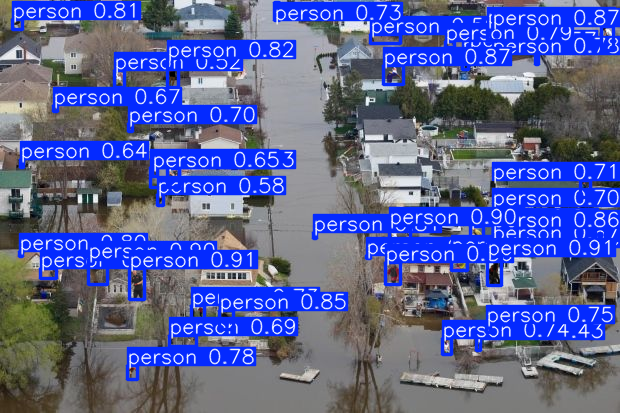

flood_image0107_4.png | Detected people: 45


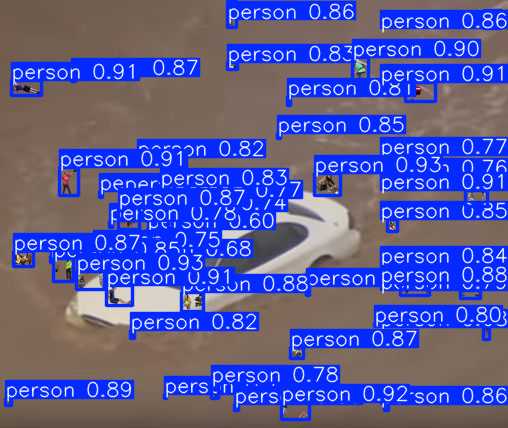

flood_image0061_4.png | Detected people: 46


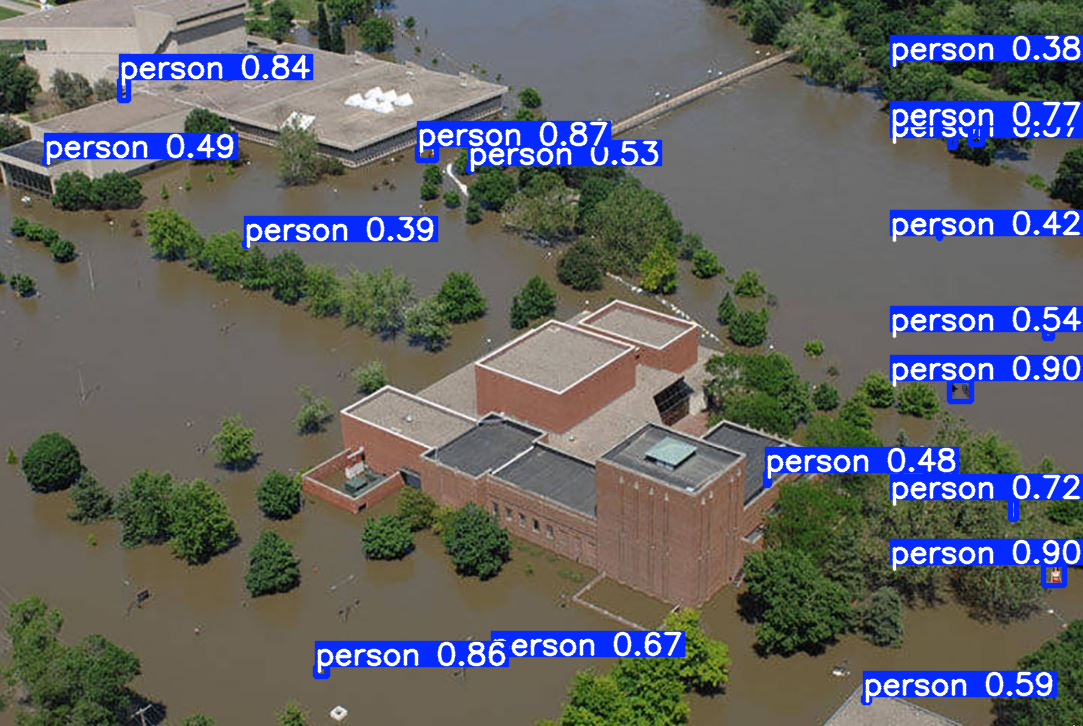

flood_image0295_0.png | Detected people: 17


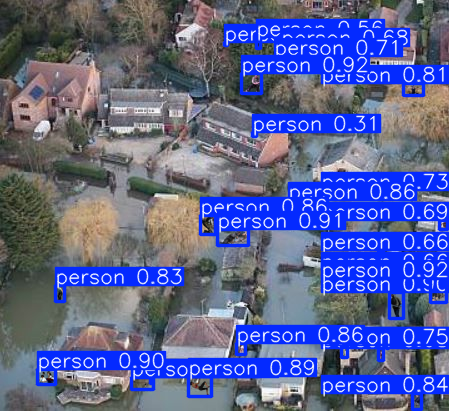

flood_image0239_1.png | Detected people: 26


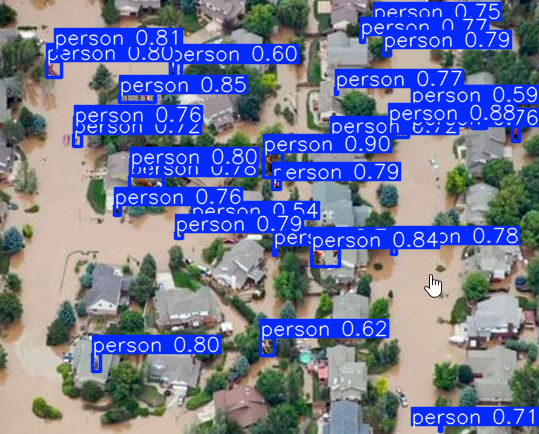

flood_image0259_0.png | Detected people: 29


In [14]:

# ==========================================
# STEP 5: VISUAL TEST PREDICTIONS
# ==========================================

import os
import random
from ultralytics import YOLO
from IPython.display import display
from PIL import Image

# Load our flood-fine-tuned model
FLOOD_MODEL_PATH = (
    "/content/drive/MyDrive/ResQVision/"
    "Outputs/yolo26m_c2a_flood_finetune_960/"
    "weights/best.pt"
)

# Test image directory
TEST_IMAGE_DIR = (
    "/content/drive/MyDrive/ResQVision/"
    "Datasets/Processed/C2A_Flood_Only/"
    "images/test"
)

model = YOLO(FLOOD_MODEL_PATH)

# Get test image filenames
image_files = [
    f for f in os.listdir(TEST_IMAGE_DIR)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
]

# Select five random images
random.seed(42)

selected_images = random.sample(
    image_files,
    min(5, len(image_files))
)

print("Displaying flood model predictions...")

# Run prediction on each selected image
for filename in selected_images:

    image_path = os.path.join(
        TEST_IMAGE_DIR,
        filename
    )

    results = model.predict(
        source=image_path,
        imgsz=1280,
        conf=0.25,
        device=0,
        verbose=False
    )

    # Display image with predicted bounding boxes
    plotted_image = results[0].plot()

    display(
        Image.fromarray(plotted_image[:, :, ::-1])
    )

    print(
        filename,
        "| Detected people:",
        len(results[0].boxes)
    )


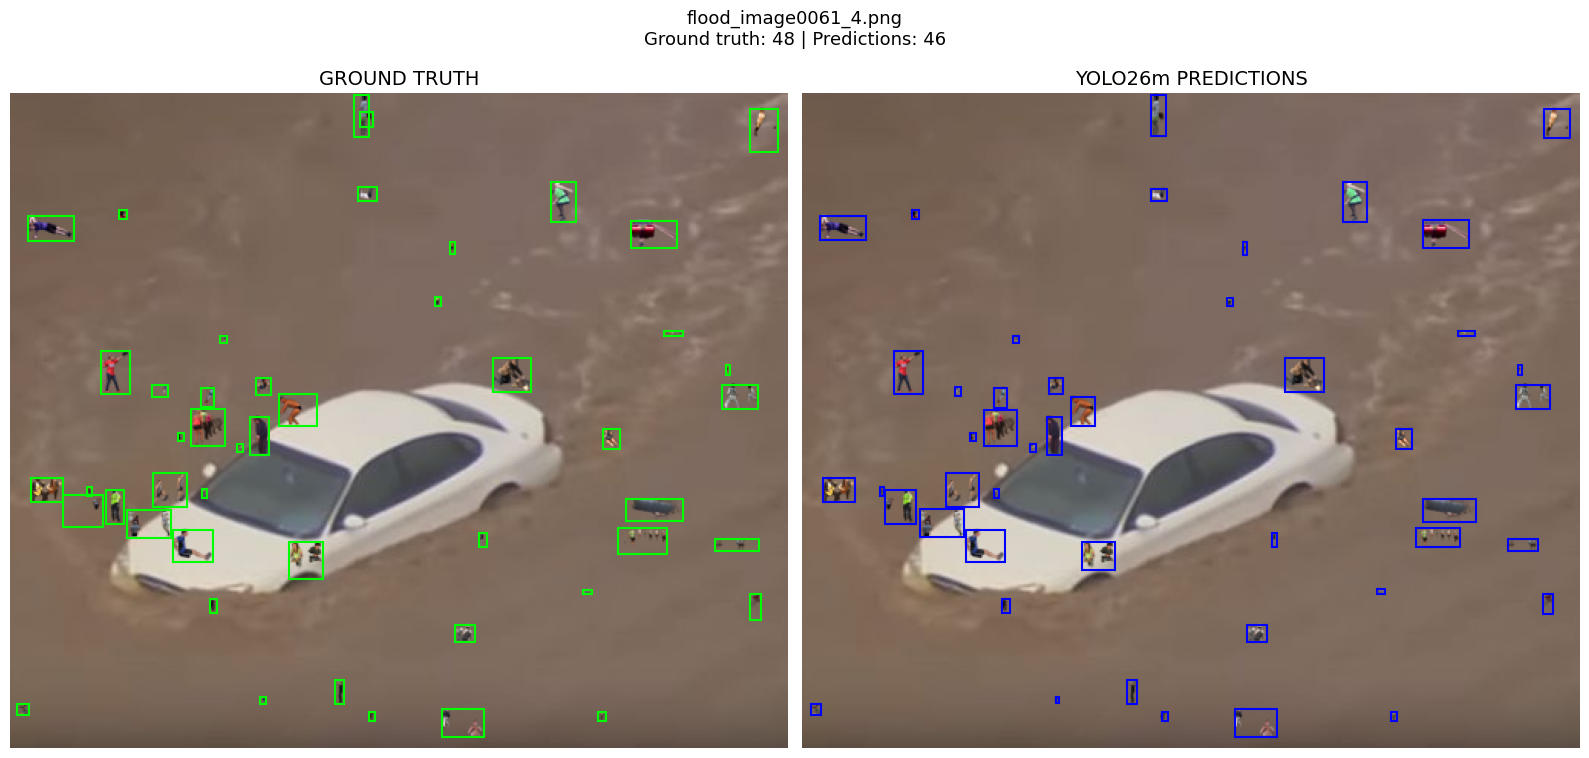

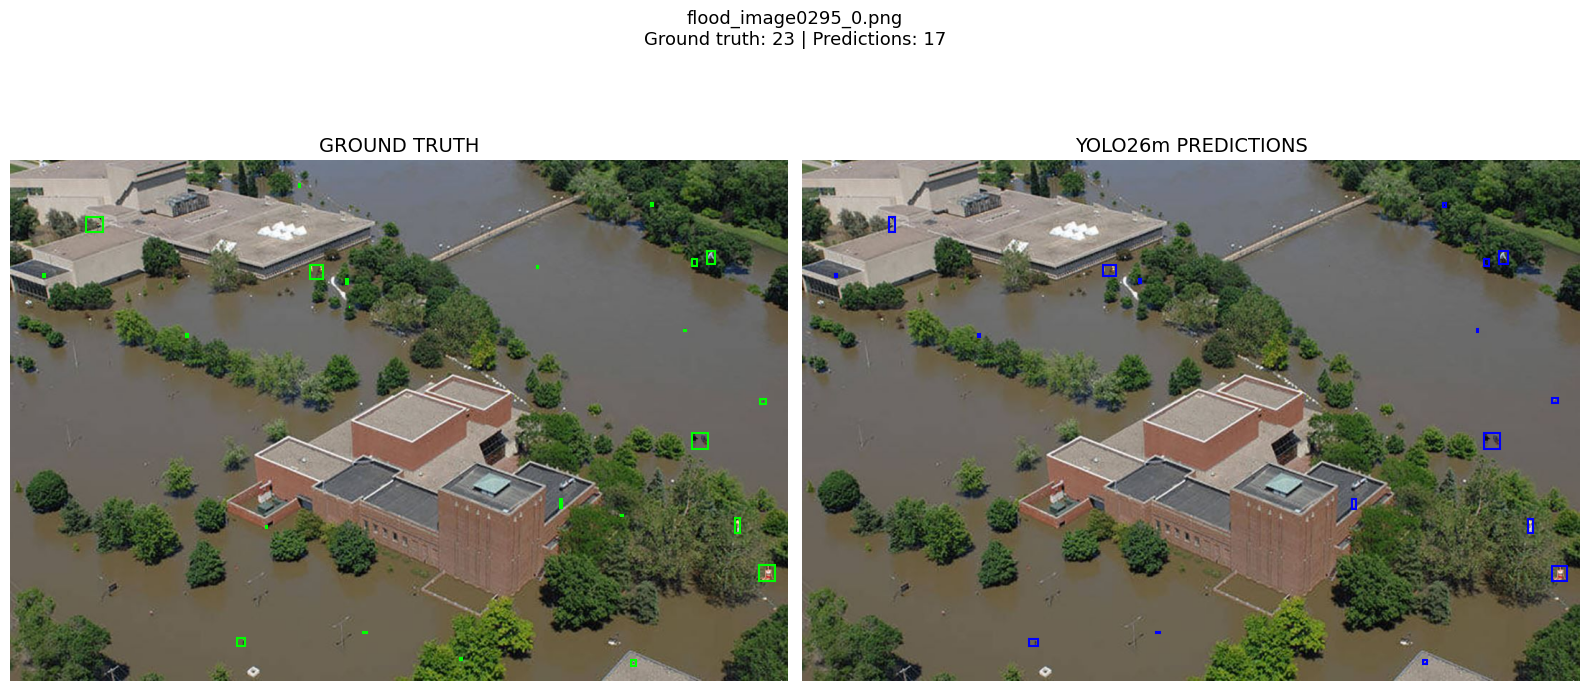

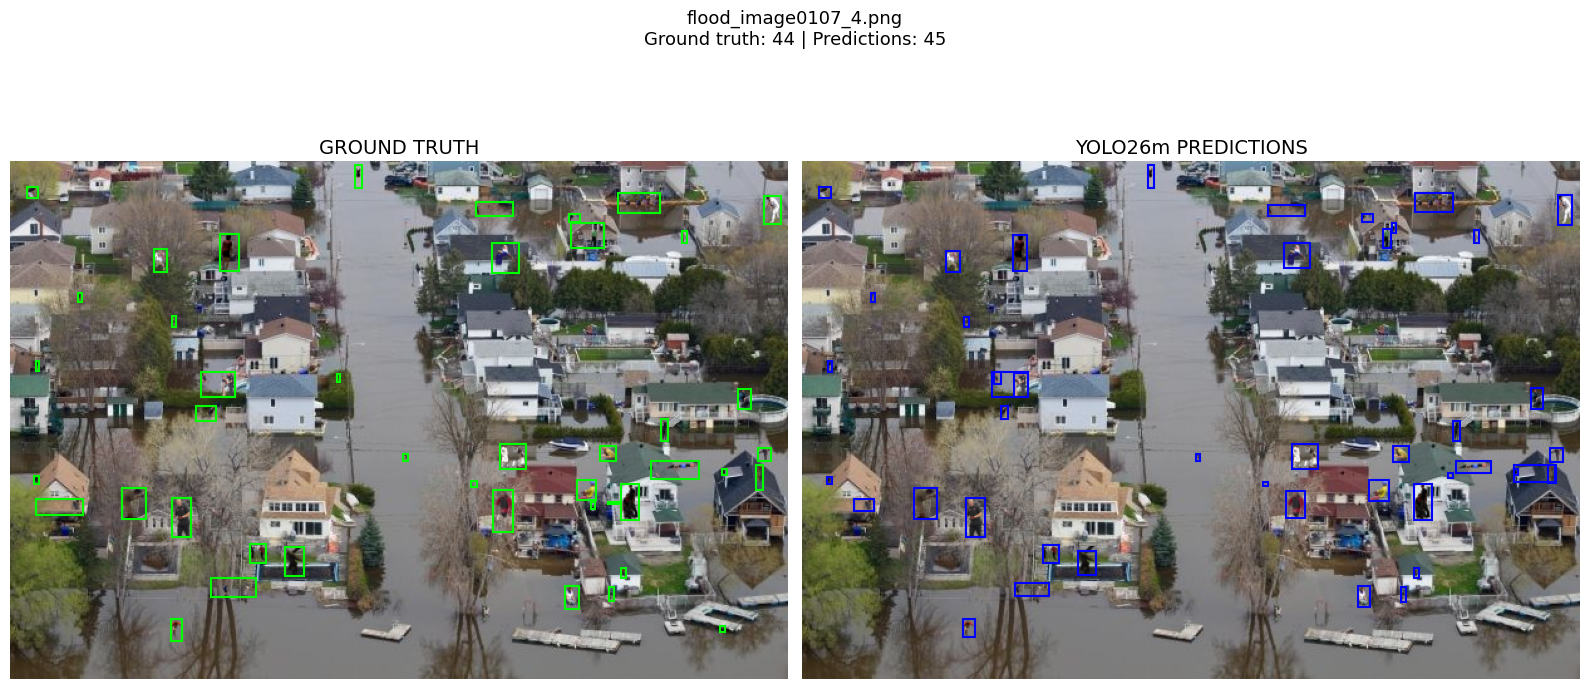

Ground-truth comparison completed!


In [16]:

# ==========================================
# STEP 6: GROUND TRUTH VS MODEL PREDICTIONS
# ==========================================

import os
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from matplotlib.lines import Line2D
from PIL import Image
from ultralytics import YOLO

# ------------------------------------------
# 1. Load our flood-fine-tuned model
# ------------------------------------------

FLOOD_MODEL_PATH = (
    "/content/drive/MyDrive/ResQVision/"
    "Outputs/yolo26m_c2a_flood_finetune_960/"
    "weights/best.pt"
)

model = YOLO(FLOOD_MODEL_PATH)

# ------------------------------------------
# 2. Set test image and label locations
# ------------------------------------------

TEST_IMAGE_DIR = (
    "/content/drive/MyDrive/ResQVision/"
    "Datasets/Processed/C2A_Flood_Only/"
    "images/test"
)

TEST_LABEL_DIR = (
    "/content/drive/MyDrive/ResQVision/"
    "Datasets/Processed/C2A_Flood_Only/"
    "labels/test"
)

# Three images selected from our previous inspection
selected_images = [
    "flood_image0061_4.png",
    "flood_image0295_0.png",
    "flood_image0107_4.png"
]

# ------------------------------------------
# 3. Compare each image
# ------------------------------------------

for filename in selected_images:

    image_path = os.path.join(TEST_IMAGE_DIR, filename)

    label_filename = os.path.splitext(filename)[0] + ".txt"
    label_path = os.path.join(TEST_LABEL_DIR, label_filename)

    # Check that both files exist
    if not os.path.exists(image_path):
        print("Image not found:", filename)
        continue

    if not os.path.exists(label_path):
        print("Label not found:", label_filename)
        continue

    # Open original image
    image = Image.open(image_path).convert("RGB")

    width, height = image.size

    # --------------------------------------
    # 4. Run model prediction
    # --------------------------------------

    results = model.predict(
        source=image_path,
        imgsz=1280,
        conf=0.25,
        device=0,
        verbose=False
    )

    predictions = results[0].boxes

    # --------------------------------------
    # 5. Create two comparison panels
    # --------------------------------------

    fig, axes = plt.subplots(1, 2, figsize=(16, 8))

    # LEFT: Ground truth annotations
    axes[0].imshow(image)
    axes[0].set_title("GROUND TRUTH", fontsize=14)

    ground_truth_count = 0

    with open(label_path, "r") as file:
        lines = file.readlines()

    for line in lines:

        values = line.strip().split()

        if len(values) != 5:
            continue

        class_id, xc, yc, box_width, box_height = map(float, values)

        # Convert normalized coordinates to pixels
        x1 = (xc - box_width / 2) * width
        y1 = (yc - box_height / 2) * height

        pixel_width = box_width * width
        pixel_height = box_height * height

        # Draw green ground-truth box
        rectangle = patches.Rectangle(
            (x1, y1),
            pixel_width,
            pixel_height,
            linewidth=1.5,
            edgecolor="lime",
            facecolor="none"
        )

        axes[0].add_patch(rectangle)

        ground_truth_count += 1

    # RIGHT: Model predictions
    axes[1].imshow(image)
    axes[1].set_title("YOLO26m PREDICTIONS", fontsize=14)

    prediction_count = 0

    if predictions is not None:

        predicted_boxes = predictions.xyxy.cpu().numpy()
        predicted_confidences = predictions.conf.cpu().numpy()

        for box, confidence in zip(
            predicted_boxes,
            predicted_confidences
        ):

            x1, y1, x2, y2 = box

            # Draw blue prediction box
            rectangle = patches.Rectangle(
                (x1, y1),
                x2 - x1,
                y2 - y1,
                linewidth=1.5,
                edgecolor="blue",
                facecolor="none"
            )

            axes[1].add_patch(rectangle)

            prediction_count += 1

    # Hide axis markings
    axes[0].axis("off")
    axes[1].axis("off")

    # Add image information
    fig.suptitle(
        filename +
        f"\nGround truth: {ground_truth_count}"
        f" | Predictions: {prediction_count}",
        fontsize=13
    )

    plt.tight_layout()
    plt.show()

print("Ground-truth comparison completed!")


In [11]:

# ==========================================
# STEP 7: TP, FP AND FN CALCULATION
# ==========================================

import os
import numpy as np
from ultralytics import YOLO

# ------------------------------------------
# 1. Load our trained model
# ------------------------------------------

FLOOD_MODEL_PATH = (
    "/content/drive/MyDrive/ResQVision/"
    "Outputs/yolo26m_c2a_flood_finetune_960/"
    "weights/best.pt"
)

TEST_IMAGE_DIR = (
    "/content/drive/MyDrive/ResQVision/"
    "Datasets/Processed/C2A_Flood_Only/"
    "images/test"
)

TEST_LABEL_DIR = (
    "/content/drive/MyDrive/ResQVision/"
    "Datasets/Processed/C2A_Flood_Only/"
    "labels/test"
)

model = YOLO(FLOOD_MODEL_PATH)

# Images we inspected earlier
selected_images = [
    "flood_image0061_4.png",
    "flood_image0295_0.png",
    "flood_image0107_4.png"
]

# Evaluation settings
CONFIDENCE = 0.25
IOU_THRESHOLD = 0.50


# ------------------------------------------
# 2. Function to calculate IoU
# ------------------------------------------

def calculate_iou(box1, box2):

    # Find the overlapping area
    x1 = max(box1[0], box2[0])
    y1 = max(box1[1], box2[1])

    x2 = min(box1[2], box2[2])
    y2 = min(box1[3], box2[3])

    intersection_width = max(0, x2 - x1)
    intersection_height = max(0, y2 - y1)

    intersection_area = (
        intersection_width * intersection_height
    )

    # Calculate area of both boxes
    area1 = (
        (box1[2] - box1[0]) *
        (box1[3] - box1[1])
    )

    area2 = (
        (box2[2] - box2[0]) *
        (box2[3] - box2[1])
    )

    # Calculate total combined area
    union_area = area1 + area2 - intersection_area

    if union_area <= 0:
        return 0

    return intersection_area / union_area


# ------------------------------------------
# 3. Evaluate each selected image
# ------------------------------------------

total_tp = 0
total_fp = 0
total_fn = 0

print("========== DETECTION MATCHING RESULTS ==========")

for filename in selected_images:

    image_path = os.path.join(
        TEST_IMAGE_DIR, filename
    )

    label_filename = (
        os.path.splitext(filename)[0] + ".txt"
    )

    label_path = os.path.join(
        TEST_LABEL_DIR, label_filename
    )

    # Read the image dimensions
    from PIL import Image

    image = Image.open(image_path)
    width, height = image.size

    # Read ground-truth boxes
    ground_truth_boxes = []

    with open(label_path, "r") as file:

        for line in file:

            values = line.strip().split()

            if len(values) != 5:
                continue

            class_id, xc, yc, w, h = map(float, values)

            # Convert YOLO format to pixel coordinates
            x1 = (xc - w / 2) * width
            y1 = (yc - h / 2) * height
            x2 = (xc + w / 2) * width
            y2 = (yc + h / 2) * height

            ground_truth_boxes.append(
                [x1, y1, x2, y2]
            )

    # Run model prediction
    results = model.predict(
        source=image_path,
        imgsz=1280,
        conf=CONFIDENCE,
        device=0,
        verbose=False
    )

    # Get predicted boxes and confidence scores
    predictions = results[0].boxes

    predicted_boxes = predictions.xyxy.cpu().numpy()
    predicted_confidences = predictions.conf.cpu().numpy()

    # Match predictions in highest-confidence-first order
    sorted_indices = np.argsort(
        -predicted_confidences
    )

    matched_ground_truth = set()

    tp = 0
    fp = 0

    for prediction_index in sorted_indices:

        predicted_box = predicted_boxes[prediction_index]

        best_iou = 0
        best_gt_index = -1

        # Find the best unmatched ground-truth box
        for gt_index, gt_box in enumerate(ground_truth_boxes):

            if gt_index in matched_ground_truth:
                continue

            iou = calculate_iou(
                predicted_box,
                gt_box
            )

            if iou > best_iou:
                best_iou = iou
                best_gt_index = gt_index

        # Count a true positive if IoU is high enough
        if best_iou >= IOU_THRESHOLD:

            tp += 1
            matched_ground_truth.add(best_gt_index)

        else:

            fp += 1

    # Ground-truth boxes that were not matched
    fn = len(ground_truth_boxes) - tp

    total_tp += tp
    total_fp += fp
    total_fn += fn

    print("\nImage:", filename)
    print("TP:", tp)
    print("FP:", fp)
    print("FN:", fn)

# ------------------------------------------
# 4. Calculate overall metrics
# ------------------------------------------

precision = total_tp / (total_tp + total_fp) if (total_tp + total_fp) > 0 else 0

recall = total_tp / (total_tp + total_fn) if (total_tp + total_fn) > 0 else 0

f1_score = (
    2 * precision * recall / (precision + recall)
    if (precision + recall) > 0 else 0
)

print("\n========== OVERALL RESULTS ==========")

print("Total TP:", total_tp)
print("Total FP:", total_fp)
print("Total FN:", total_fn)

print("Precision:", round(precision, 4))
print("Recall:", round(recall, 4))
print("F1 Score:", round(f1_score, 4))


========== DETECTION MATCHING RESULTS ==========

Image: flood_image0061_4.png
TP: 44
FP: 2
FN: 4

Image: flood_image0295_0.png
TP: 15
FP: 2
FN: 8

Image: flood_image0107_4.png
TP: 36
FP: 9
FN: 8

========== OVERALL RESULTS ==========
Total TP: 95
Total FP: 13
Total FN: 20
Precision: 0.8796
Recall: 0.8261
F1 Score: 0.852
